# Phase 3 — Allocation: does a complement + a rule beat carry alone?

**Question.** Carry is regime-gated (rich 2021/2024, dead 2022/2023/2025) and near-orthogonal to the
Phase-2 trend/momentum sleeves. Does combining carry with a diversifier — statically, or with a
mechanism-first dynamic rotation — improve the risk-adjusted return, and specifically **fill in the
carry-dead years**? The classic prior is that **static diversification captures most of the benefit**;
we test that honestly, then test exactly ONE dynamic rule.

**Preregistration.** The candidate diversifier set is defined mechanically (monthly corr < 0.30 to
carry AND positive full-sample excess) and computed below. Four allocation trials only — three static,
one dynamic — all enumerated in the ledger; **no parameter grid search on the allocation**. All in
excess of rf; every vol scaling is ex-post and labeled.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.regime_atlas.atlas_lab as A
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,PURPLE,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#6a4c93','0.55'
YR=[2021,2022,2023,2024,2025,2026]

didx = A.date_grid(); rf_a = A.rf_annual(didx); rf_d = A.rf_daily(didx); C = A.costs()
SC, DV = A.spot_daily(A.registry_symbols('spot'), didx)
memb, adv = A.liquid_membership(DV)
union = memb.columns[memb.any()].tolist()
union_perp = [s for s in union if s in set(A.registry_symbols('perps'))]
PC, FS = A.perp_daily(union_perp, didx); memb_p = memb[union_perp]; pool = A.liquid_pool(adv,5e6)

EX = {
 'CARRY':       A.carry_excess(didx),
 'TS-TREND-LF': A.sleeve_ts_trend_lf(SC, rf_d, C['spot_oneway'])['excess'],
 'TS-TREND-LS': A.sleeve_ts_trend_ls(PC, FS, memb_p, C['perp_oneway'])['excess'],
 'XS-MOM':      A.sleeve_xs_mom(PC, FS, memb_p, C['perp_oneway'])['excess'],
 'REV':         A.sleeve_rev(PC, FS, memb_p, C['perp_oneway'])['excess'],
 'BETA-BTC':    A.sleeve_beta_btc(SC, rf_d)['excess'],
 'BETA-EW':     A.sleeve_beta_ew(SC, memb, rf_d, C['spot_oneway'])['excess'],
}
print('sleeves built:', list(EX))

2026-07-06 16:48:01,203 WARNING  query | no data for spot/binance/lendusdt/bars (stage=auto); returning empty frame


2026-07-06 16:48:02,636 WARNING  query | no data for spot/binance/币安人生usdt/bars (stage=auto); returning empty frame


sleeves built: ['CARRY', 'TS-TREND-LF', 'TS-TREND-LS', 'XS-MOM', 'REV', 'BETA-BTC', 'BETA-EW']


## 1. Declare the candidate diversifier set (mechanical)

Monthly-excess correlation to carry and full-sample excess return for every Phase-2 sleeve. The
candidate set is exactly those with **corr < 0.30 AND positive excess** — chosen by rule, not by eye.

In [2]:
MO = pd.DataFrame({k:v.resample('ME').sum() for k,v in EX.items()})
scan = pd.DataFrame({'corr_vs_carry': MO.corr()['CARRY'],
                     'fullsample_excess%': pd.Series({k:A.ann_stats(v)['ann_return']*100 for k,v in EX.items()})})
scan['candidate'] = (scan['corr_vs_carry']<0.30) & (scan['fullsample_excess%']>0) & (scan.index!='CARRY')
print(scan.round(2).to_string())
CAND = scan.index[scan['candidate']].tolist()
print('\nCANDIDATE SET:', CAND)

             corr_vs_carry  fullsample_excess%  candidate
CARRY                 1.00                7.37      False
TS-TREND-LF           0.19               32.69       True
TS-TREND-LS           0.10               25.24       True
XS-MOM                0.03               30.63       True
REV                  -0.18              -29.75      False
BETA-BTC              0.31               30.62      False
BETA-EW               0.43               -8.80      False

CANDIDATE SET: ['TS-TREND-LF', 'TS-TREND-LS', 'XS-MOM']


## 2. Static mixes vs carry alone

Three static rules. **A (50/50 native)** splits capital evenly between carry and the equal-weight
candidate basket — but carry's ~1.5% vol vs the basket's ~40%+ means this is really *almost all trend
risk*. **B (equal-risk)** weights by 1/vol, which for a Sharpe-5, 1.5%-vol carry book puts **~95% in
carry** — so risk-parity ≈ carry-alone. **C (50/50 vol-matched)** scales carry and the basket each to
10% ann. vol first, then 50/50 — the only apples-to-apples "diversification" test. All vol scalings
are ex-post (full-sample); the equity curves use those fixed leverages.

In [3]:
def fs_scale(ex, target=0.10):
    v = ex.dropna().std()*np.sqrt(365); return (target/v) if v>0 else 0.0
basket = pd.concat([EX[k] for k in CAND],axis=1).mean(axis=1)          # EW candidate basket (native)
carry = EX['CARRY']
# A: native 50/50
mixA = 0.5*carry + 0.5*basket
# B: equal-risk (inverse full-sample vol) across CARRY + candidates
assets = ['CARRY']+CAND
ivw = pd.Series({k: 1.0/(EX[k].dropna().std()*np.sqrt(365)) for k in assets}); ivw/=ivw.sum()
mixB = sum(ivw[k]*EX[k] for k in assets)
# C: vol-matched 50/50 (each leg to 10% vol, then 50/50)
carry10 = carry*fs_scale(carry); basket10 = basket*fs_scale(basket)
mixC = 0.5*carry10 + 0.5*basket10
carry10_only = carry10                                                 # carry-alone at 10% vol, for C-comparison
BOOKS = {'CARRY (native)':carry,'A: 50/50 native':mixA,'B: equal-risk':mixB,
         'carry@10%':carry10_only,'C: 50/50 vol-match':mixC}
print('equal-risk weights:', ivw.round(3).to_dict())
def kpi(ex):
    s=A.ann_stats(ex); return {'excess%':round(s['ann_return']*100,2),'vol%':round(s['ann_vol']*100,1),
        'Sharpe':round(s['sharpe'],2),'maxDD%':round(s['max_dd']*100,2),
        'Calmar':round(s['calmar'],2) if np.isfinite(s['calmar']) else np.nan}
print(pd.DataFrame({k:kpi(v) for k,v in BOOKS.items()}).T.to_string())

equal-risk weights: {'CARRY': 0.926, 'TS-TREND-LF': 0.033, 'TS-TREND-LS': 0.019, 'XS-MOM': 0.021}
                    excess%  vol%  Sharpe  maxDD%  Calmar
CARRY (native)         7.37   1.5    4.99   -1.72    4.28
A: 50/50 native       18.67  19.8    0.94  -26.62    0.70
B: equal-risk          9.08   3.0    3.00   -3.37    2.70
carry@10%             49.89  10.0    4.99  -11.65    4.28
C: 50/50 vol-match    28.75   7.1    4.05   -7.30    3.94


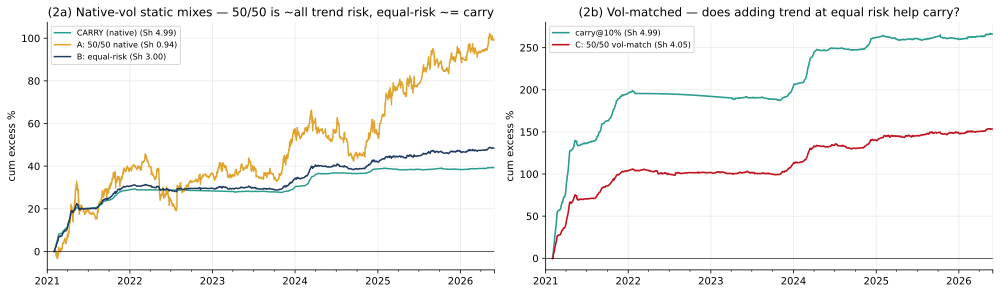

In [4]:
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4.2))
for k,c in [('CARRY (native)',TEAL),('A: 50/50 native',AMBER),('B: equal-risk',NAVY)]:
    (BOOKS[k].cumsum()*100).plot(ax=a1,color=c,lw=1.5,label=f"{k} (Sh {A.ann_stats(BOOKS[k])['sharpe']:.2f})")
a1.axhline(0,color='k',lw=0.6); a1.set_ylabel('cum excess %'); a1.legend(fontsize=8)
a1.set_title('(2a) Native-vol static mixes — 50/50 is ~all trend risk, equal-risk ~= carry')
for k,c in [('carry@10%',TEAL),('C: 50/50 vol-match',RED)]:
    (BOOKS[k].cumsum()*100).plot(ax=a2,color=c,lw=1.6,label=f"{k} (Sh {A.ann_stats(BOOKS[k])['sharpe']:.2f})")
a2.axhline(0,color='k',lw=0.6); a2.set_ylabel('cum excess %'); a2.legend(fontsize=8)
a2.set_title('(2b) Vol-matched — does adding trend at equal risk help carry?'); plt.tight_layout(); plt.show()

## 3. The ONE dynamic rule — opportunity-weighted carry vs trend

Mechanism-first, preregistered, no search. Each sleeve's weight tracks *its own* point-in-time
opportunity. CARRY: how far median funding APR exceeds rf plus an amortized cost hurdle. TREND: how far
the share of the liquid universe *in trend* exceeds its own expanding median. Renormalize; sit in CASH
(excess 0) when neither opportunity is positive. Sleeves are put on a common 10% vol footing; the mix
is rebalanced monthly. TREND sleeve = TS-TREND-LS (the universe long/short book the breadth signal
describes).

In [5]:
# opportunity signals (point-in-time)
carry_turn_yr = pd.read_parquet(A.CARRY_RESULTS)['turnover'].mean()*365
H_carry = C['carry_pair_oneway']*carry_turn_yr
fund_apr = FS.rolling(30,min_periods=15).mean()*365
med_apr = fund_apr.where(memb_p).median(axis=1)
carry_opp = (med_apr - rf_a - H_carry).clip(lower=0.0)
ma100 = SC.rolling(100,min_periods=50).mean(); vol20 = SC.rolling(20,min_periods=10).std()
in_trend = ((SC-ma100).abs() > vol20) & pool & SC.notna()
trend_frac = in_trend.sum(axis=1)/(pool & SC.notna()).sum(axis=1).replace(0,np.nan)
trend_opp = (trend_frac - trend_frac.expanding(min_periods=60).median()).clip(lower=0.0)
print(f'H_carry (amortized cost hurdle) = {H_carry*100:.2f}%/yr  (carry turnover {carry_turn_yr:.1f}x)')

# monthly mix weights, common 10% vol footing, TREND = TS-TREND-LS
mo = pd.date_range(didx[0],didx[-1],freq='MS')
co = carry_opp.reindex(mo,method='ffill').fillna(0.0); to = trend_opp.reindex(mo,method='ffill').fillna(0.0)
tot = co+to
wc = (co/tot.where(tot>0,np.nan)).fillna(0.0); wt = (to/tot.where(tot>0,np.nan)).fillna(0.0)
Wc = wc.reindex(didx,method='ffill').fillna(0.0); Wt = wt.reindex(didx,method='ffill').fillna(0.0)
trend10 = EX['TS-TREND-LS']*fs_scale(EX['TS-TREND-LS'])
dynamic = Wc.shift(1).fillna(0.0)*carry10 + Wt.shift(1).fillna(0.0)*trend10     # cash residual -> excess 0
mixW = pd.DataFrame({'w_carry':Wc,'w_trend':Wt,'w_cash':1-Wc-Wt})
print('mix weights by year (mean):'); print(mixW.groupby(mixW.index.year).mean().round(2).to_string())

H_carry (amortized cost hurdle) = 2.25%/yr  (carry turnover 11.8x)
mix weights by year (mean):
      w_carry  w_trend  w_cash
2021     0.81     0.10    0.08
2022     0.13     0.62    0.25
2023     0.15     0.43    0.42
2024     0.56     0.35    0.08
2025     0.19     0.39    0.42
2026     0.00     0.79    0.21


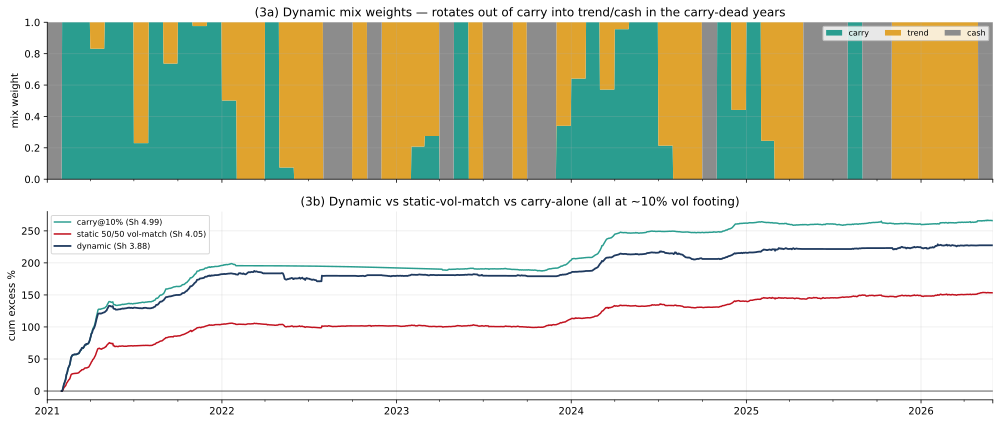

In [6]:
fig,(a1,a2)=plt.subplots(2,1,figsize=(14,6),sharex=True,gridspec_kw={'height_ratios':[1,1.2]})
a1.stackplot(didx, Wc, Wt, (1-Wc-Wt).clip(lower=0), colors=[TEAL,AMBER,GREY], labels=['carry','trend','cash'])
a1.set_ylim(0,1); a1.set_ylabel('mix weight'); a1.legend(loc='upper right',fontsize=8,ncol=3)
a1.set_title('(3a) Dynamic mix weights — rotates out of carry into trend/cash in the carry-dead years')
(carry10.cumsum()*100).plot(ax=a2,color=TEAL,lw=1.5,label=f'carry@10% (Sh {A.ann_stats(carry10)["sharpe"]:.2f})')
(BOOKS['C: 50/50 vol-match'].cumsum()*100).plot(ax=a2,color=RED,lw=1.5,label=f'static 50/50 vol-match (Sh {A.ann_stats(BOOKS["C: 50/50 vol-match"])["sharpe"]:.2f})')
(dynamic.cumsum()*100).plot(ax=a2,color=NAVY,lw=1.8,label=f'dynamic (Sh {A.ann_stats(dynamic)["sharpe"]:.2f})')
a2.axhline(0,color='k',lw=0.6); a2.set_ylabel('cum excess %'); a2.legend(fontsize=8)
a2.set_title('(3b) Dynamic vs static-vol-match vs carry-alone (all at ~10% vol footing)'); plt.tight_layout(); plt.show()

## 4. Comparison — carry alone vs static vs dynamic

All books at the common 10%-vol footing so Sharpe/return/maxDD are comparable. Full-sample plus the
per-year table, with the **carry-dead rows (2022, 2023, 2025) called out** — the whole point is whether
diversification fills those in without giving back the carry-rich years.

In [7]:
COMPARE = {'carry@10%':carry10, 'static 50/50 vol-match':BOOKS['C: 50/50 vol-match'],
           'dynamic':dynamic, 'equal-risk (native)':mixB}
full = pd.DataFrame({k:kpi(v) for k,v in COMPARE.items()}).T
print('=== FULL SAMPLE ==='); print(full.to_string())
print('\n=== per-year EXCESS RETURN % ===')
py = pd.DataFrame({k: A.per_year(v)['excess_ret']*100 for k,v in COMPARE.items()}).reindex(YR).round(1)
print(py.to_string())
print('\n=== per-year SHARPE ===')
ps = pd.DataFrame({k: A.per_year(v)['sharpe'] for k,v in COMPARE.items()}).reindex(YR).round(2)
print(ps.to_string())
print('\n=== carry-dead years (excess %) ===')
print(py.loc[[2022,2023,2025]].to_string())

=== FULL SAMPLE ===
                        excess%  vol%  Sharpe  maxDD%  Calmar
carry@10%                 49.89  10.0    4.99  -11.65    4.28
static 50/50 vol-match    28.75   7.1    4.05   -7.30    3.94
dynamic                   42.63  11.0    3.88  -16.32    2.61
equal-risk (native)        9.08   3.0    3.00   -3.37    2.70

=== per-year EXCESS RETURN % ===
      carry@10%  static 50/50 vol-match  dynamic  equal-risk (native)
2021      195.8                   104.1    182.3                 30.6
2022       -3.6                    -2.2     -2.5                 -0.9
2023       11.8                    10.3      4.7                  4.2
2024       58.2                    28.1     31.5                  8.3
2025       -1.6                     8.9      8.6                  4.9
2026        5.6                     4.2      2.8                  1.4

=== per-year SHARPE ===
      carry@10%  static 50/50 vol-match  dynamic  equal-risk (native)
2021      11.23                    9.91    11.02   

## 5. Trial ledger

In [8]:
alloc_ledger = pd.DataFrame([
 {'trial':'A static 50/50 native','rule':'0.5 carry + 0.5 EW(candidates)','search':'none'},
 {'trial':'B equal-risk','rule':'w ~ 1/full-sample vol over {carry,candidates}','search':'none'},
 {'trial':'C static 50/50 vol-match','rule':'carry@10% & basket@10%, 50/50','search':'none'},
 {'trial':'D dynamic rotation','rule':'w ~ own opportunity (carry funding-vs-hurdle; trend breadth-vs-median); cash fallback','search':'none'},
])
print(alloc_ledger.to_string(index=False)); print('\nPhase-3 allocation trials:', len(alloc_ledger))

                   trial                                                                                  rule search
   A static 50/50 native                                                        0.5 carry + 0.5 EW(candidates)   none
            B equal-risk                                         w ~ 1/full-sample vol over {carry,candidates}   none
C static 50/50 vol-match                                                         carry@10% & basket@10%, 50/50   none
      D dynamic rotation w ~ own opportunity (carry funding-vs-hurdle; trend breadth-vs-median); cash fallback   none

Phase-3 allocation trials: 4


## Verdict

- **Nothing beats carry alone on aggregate risk-adjusted return.** At a common 10% vol footing,
  full-sample Sharpe ranks **carry-alone 4.99 > static vol-match 4.05 > dynamic 3.88**, and Calmar
  agrees (carry 4.28 > static 3.94). Diversification *dilutes* the carry-rich years (2021, 2024) that
  dominate the aggregate metrics, so any blend gives back Sharpe. **Equal-risk (1/vol) puts ~93% in
  carry** yet still *lowers* Sharpe to 3.00 — a small trend allocation adds vol faster than return.
  A **naive native 50/50 is a trap** (Sharpe 0.94): carry's 1.5% vol means "50/50 capital" is really
  ~all trend risk.
- **Where the complement *does* earn its keep: the flat-year path, narrowly.** The vol-matched blend
  turns the worst carry-dead year around — **2025 carry −1.6% → static +8.9% / dynamic +8.6%** — and
  softens 2022 (−3.6% → −2.2%), while cutting maxDD (carry@10% −11.7% → static −7.3%). But it is **not
  uniform: it HURTS 2023** (carry levered +11.8% → static +10.3% → dynamic +4.7%), where carry alone was
  fine and trend just added noise. So the complement is a *targeted flat-year / drawdown smoother*, not
  a general upgrade.
- **Static captures the benefit; the dynamic rule does not beat it.** The rotation mechanism works as
  designed (it demonstrably shifts out of carry into trend/cash in 2022/2023/2025), but it ends up with
  **lower Sharpe (3.88 vs 4.05) and deeper maxDD (−16.3% vs −7.3%)** than the static vol-matched mix —
  its 2024 trend weight rides TS-TREND-LS's −55% year. This confirms the classic prior: **static
  diversification captures essentially all of the benefit; the extra moving parts of a dynamic rule are
  not worth it here.**
- **Recommendation.** Run **carry alone** if the objective is aggregate risk-adjusted return. If the
  objective is specifically to de-risk the carry-dead years and the drawdown path, add the diversifier
  (candidate basket, or TS-TREND-LS) **statically at equal risk (vol-matched)** — accepting a lower
  full-sample Sharpe for a smoother, less regime-gated equity curve. Do **not** build the dynamic
  rotation: it adds complexity and drawdown for no risk-adjusted gain over the static blend.